In [22]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [23]:
df=pd.read_csv("../data/netflix_titles.csv")

In [24]:
df.head()

,show_id,type,title,director,cast,country,date_added,release_year,rating,duration,listed_in,description
0,81145628,Movie,Norm of the North: King Sized Adventure,"Richard Finn, Tim Maltby","Alan Marriott, Andrew Toth, Brian Dobson, Cole...","United States, India, South Korea, China","September 9, 2019",2019,TV-PG,90 min,"Children & Family Movies, Comedies",Before planning an awesome wedding for his gra...
1,80117401,Movie,Jandino: Whatever it Takes,NaN,Jandino Asporaat,United Kingdom,"September 9, 2016",2016,TV-MA,94 min,Stand-Up Comedy,Jandino Asporaat riffs on the challenges of ra...
2,70234439,TV Show,Transformers Prime,NaN,"Peter Cullen, Sumalee Montano, Frank Welker, J...",United States,"September 8, 2018",2013,TV-Y7-FV,1 Season,Kids' TV,"With the help of three human allies, the Autob..."
3,80058654,TV Show,Transformers: Robots in Disguise,NaN,"Will Friedle, Darren Criss, Constance Zimmer, ...",United States,"September 8, 2018",2016,TV-Y7,1 Season,Kids' TV,When a prison ship crash unleashes hundreds of...
4,80125979,Movie,#realityhigh,Fernando Lebrija,"Nesta Cooper, Kate Walsh, John Michael Higgins...",United States,"September 8, 2017",2017,TV-14,99 min,Comedies,When nerdy high schooler Dani finally attracts...


In [25]:
print(df.shape)

(6234, 12)


In [26]:
print(df.columns)

Index(['show_id', 'type', 'title', 'director', 'cast', 'country', 'date_added',
       'release_year', 'rating', 'duration', 'listed_in', 'description'],
      dtype='str')


In [27]:
print(df.info())

<class 'pandas.DataFrame'>
RangeIndex: 6234 entries, 0 to 6233
Data columns (total 12 columns):
 #   Column        Non-Null Count  Dtype
---  ------        --------------  -----
 0   show_id       6234 non-null   int64
 1   type          6234 non-null   str  
 2   title         6234 non-null   str  
 3   director      4265 non-null   str  
 4   cast          5664 non-null   str  
 5   country       5758 non-null   str  
 6   date_added    6223 non-null   str  
 7   release_year  6234 non-null   int64
 8   rating        6224 non-null   str  
 9   duration      6234 non-null   str  
 10  listed_in     6234 non-null   str  
 11  description   6234 non-null   str  
dtypes: int64(2), str(10)
memory usage: 2.7 MB
None


In [28]:
print(df.describe(include='all'))

             show_id   type title                director                cast  \
count   6.234000e+03   6234  6234                    4265                5664   
unique           NaN      2  6172                    3301                5469   
top              NaN  Movie  Love  Raúl Campos, Jan Suter  David Attenborough   
freq             NaN   4265     3                      18                  18   
mean    7.670368e+07    NaN   NaN                     NaN                 NaN   
std     1.094296e+07    NaN   NaN                     NaN                 NaN   
min     2.477470e+05    NaN   NaN                     NaN                 NaN   
25%     8.003580e+07    NaN   NaN                     NaN                 NaN   
50%     8.016337e+07    NaN   NaN                     NaN                 NaN   
75%     8.024489e+07    NaN   NaN                     NaN                 NaN   
max     8.123573e+07    NaN   NaN                     NaN                 NaN   

              country      

In [29]:
print(df.isnull().sum())

show_id            0
type               0
title              0
director        1969
cast             570
country          476
date_added        11
release_year       0
rating            10
duration           0
listed_in          0
description        0
dtype: int64


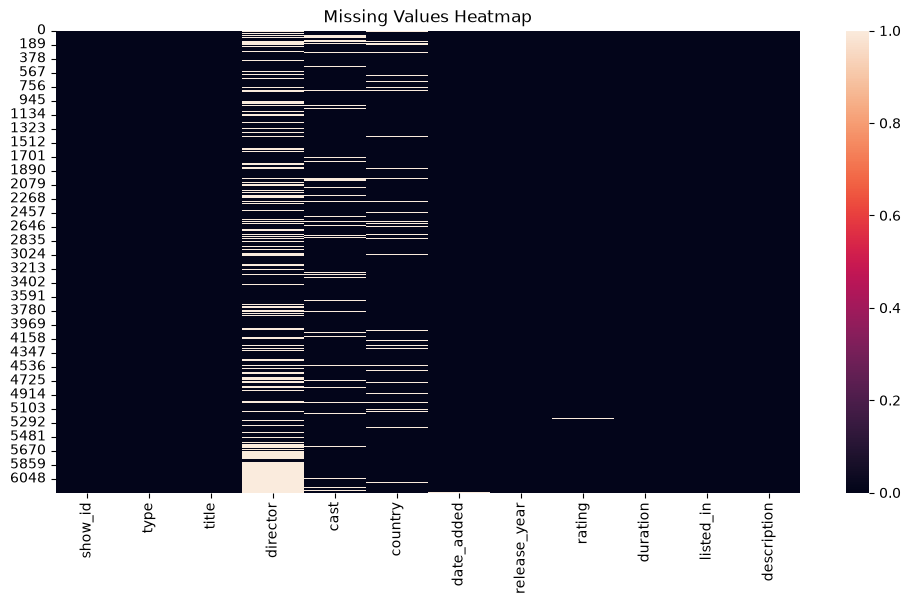

In [30]:
plt.figure(figsize=(12,6))

sns.heatmap(df.isnull())

plt.title("Missing Values Heatmap")

plt.savefig(
    "../visuals/missing_values_heatmap.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [31]:
print(df.duplicated().sum())

0


In [32]:
print(df.drop_duplicates(inplace=True))

None


In [33]:
df['date_added'].head(10)

0    September 9, 2019
1    September 9, 2016
2    September 8, 2018
3    September 8, 2018
4    September 8, 2017
5    September 8, 2017
6    September 8, 2017
7    September 8, 2017
8    September 8, 2017
9    September 8, 2017
Name: date_added, dtype: str

In [34]:
count=len(df['date_added'])
print(count)

6234


In [35]:
unique_count = len(df['date_added'].unique())
print(unique_count)

1525


In [36]:
df['date_added'].unique()[:10]

<ArrowStringArray>
['September 9, 2019', 'September 9, 2016', 'September 8, 2018',
 'September 8, 2017', 'September 8, 2015', 'September 7, 2018',
 'September 7, 2017', 'September 6, 2019', 'September 6, 2018',
 'September 6, 2017']
Length: 10, dtype: str

In [37]:
df[df['date_added'].str.startswith(' ',na=False)][['date_added']].head(20)

,date_added
5583,"September 9, 2018"
5584,"September 8, 2017"
5585,"September 8, 2015"
5586,"September 7, 2018"
5587,"September 7, 2018"
5588,"September 7, 2016"
5589,"September 6, 2019"
5590,"September 6, 2019"
5591,"September 6, 2018"
5592,"September 5, 2017"


In [38]:
total_count=df[df['date_added'].astype(str).str.startswith(' ',na=False)].shape[0]
print(total_count)

640


In [39]:
df['date_added']=df['date_added'].str.strip()

In [40]:
df['date_added'].head()

0    September 9, 2019
1    September 9, 2016
2    September 8, 2018
3    September 8, 2018
4    September 8, 2017
Name: date_added, dtype: str

In [41]:
df[df['date_added'].str.startswith(' ',na=False)][['date_added']].head(20)

,date_added


In [42]:
df['date_added']=pd.to_datetime(
    df['date_added'],
    errors='coerce'
)

In [43]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 6234 entries, 0 to 6233
Data columns (total 12 columns):
 #   Column        Non-Null Count  Dtype         
---  ------        --------------  -----         
 0   show_id       6234 non-null   int64         
 1   type          6234 non-null   str           
 2   title         6234 non-null   str           
 3   director      4265 non-null   str           
 4   cast          5664 non-null   str           
 5   country       5758 non-null   str           
 6   date_added    6223 non-null   datetime64[us]
 7   release_year  6234 non-null   int64         
 8   rating        6224 non-null   str           
 9   duration      6234 non-null   str           
 10  listed_in     6234 non-null   str           
 11  description   6234 non-null   str           
dtypes: datetime64[us](1), int64(2), str(9)
memory usage: 2.6 MB


In [44]:
df['year_added']=df['date_added'].dt.year

In [45]:
print(df[['date_added','year_added']].head())

  date_added  year_added
0 2019-09-09      2019.0
1 2016-09-09      2016.0
2 2018-09-08      2018.0
3 2018-09-08      2018.0
4 2017-09-08      2017.0


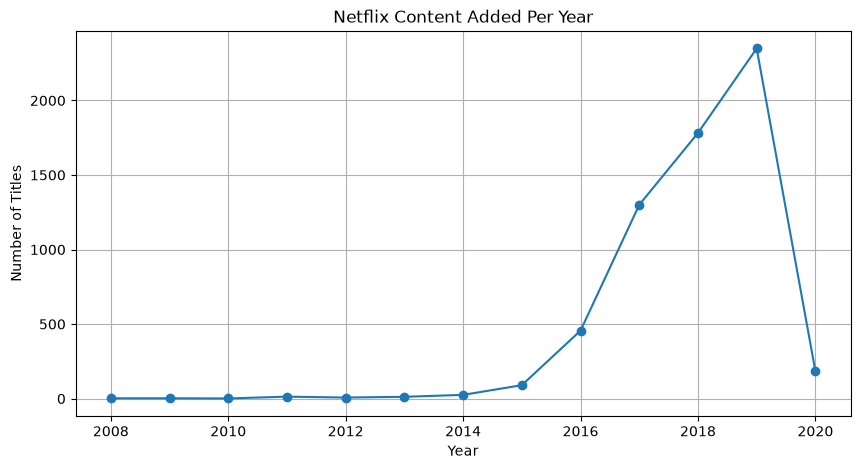

In [46]:
content_per_year=(
    df.groupby('year_added')
    .size()
)

plt.figure(figsize=(10,5))
plt.plot(
    content_per_year.index,
    content_per_year.values,
    marker='o'
)

plt.title('Netflix Content Added Per Year')
plt.xlabel('Year')
plt.ylabel('Number of Titles')
plt.grid(True)
plt.savefig("../visuals/content_per_year",
            dpi=300,
            bbox_inches="tight"
            )
plt.show()

In [47]:
df['country'].value_counts().head(20)

country
United States                    2032
India                             777
United Kingdom                    348
Japan                             176
Canada                            141
South Korea                       136
Spain                             117
France                             90
Mexico                             83
Turkey                             79
Australia                          71
Taiwan                             69
Hong Kong                          51
Thailand                           50
United Kingdom, United States      50
Brazil                             50
China                              50
Egypt                              50
Indonesia                          44
Philippines                        44
Name: count, dtype: int64

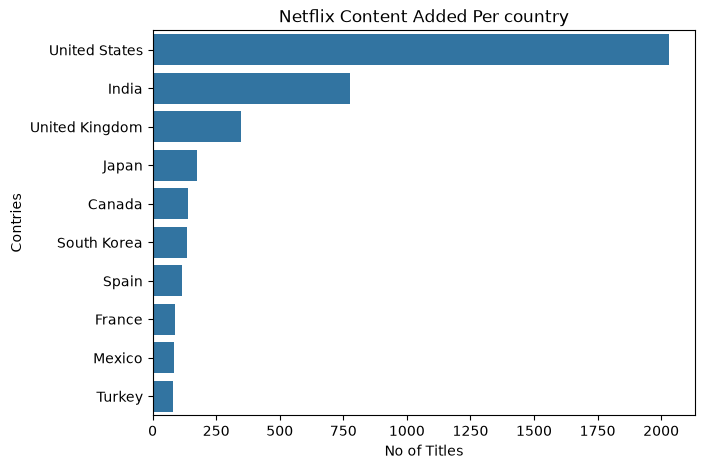

In [51]:
content_per_country=(
    df['country']
    .value_counts()
    .head(10)
)
plt.figure(figsize=(7,5))

sns.barplot(
    x=content_per_country.values,
    y=content_per_country.index
)
plt.title('Netflix Content Added Per country')
plt.xlabel('No of Titles')
plt.ylabel('Contries')
plt.savefig("../visuals/content_added_per_country",
            dpi=300,
            bbox_inches="tight")
plt.show()

In [49]:
df['rating'].value_counts()

rating
TV-MA       2027
TV-14       1698
TV-PG        701
R            508
PG-13        286
NR           218
PG           184
TV-Y7        169
TV-G         149
TV-Y         143
TV-Y7-FV      95
G             37
UR             7
NC-17          2
Name: count, dtype: int64

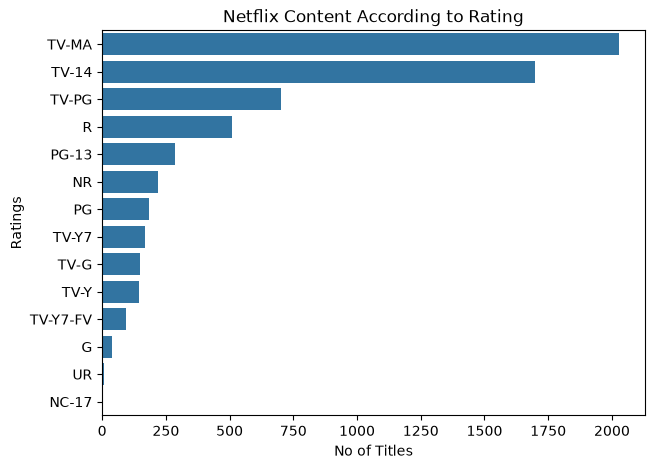

In [53]:
content_per_rating=(
    df['rating']
    .value_counts()
)
plt.figure(figsize=(7,5))

sns.barplot(
    x=content_per_rating.values,
    y=content_per_rating.index
)
plt.title('Netflix Content According to Rating')
plt.xlabel('No of Titles')
plt.ylabel('Ratings')
plt.savefig("../visuals/content_according_to_raing",
            dpi=300,
            bbox_inches="tight")
plt.show()

In [54]:
content_per_year=df.groupby('year_added').size()
growth =content_per_year.pct_change() * 100

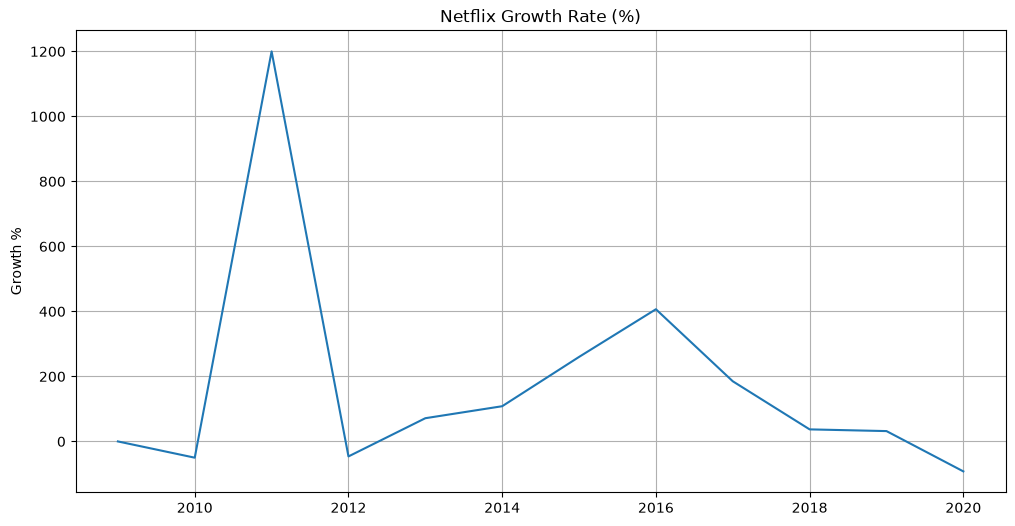

<Figure size 640x480 with 0 Axes>

In [56]:
plt.figure(figsize=(12,6))
plt.plot(growth.index,growth.values)
plt.title("Netflix Growth Rate (%)")
plt.ylabel("Growth %")
plt.grid(True)
plt.show()

plt.savefig("../visuals/growth_rate",
            dpi=300,
            bbox_inches="tight")

In [59]:
geners=(df['listed_in'].str.strip(', ').explode())
top_geners=geners.value_counts().head(15)

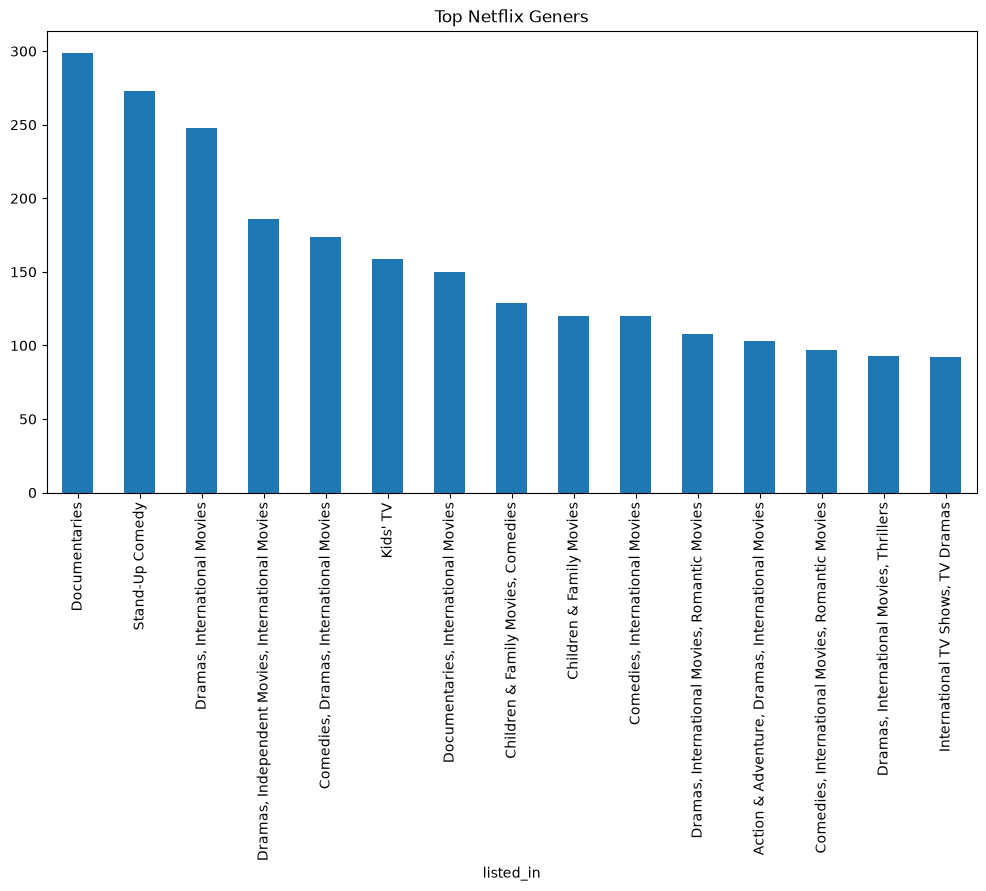

<Figure size 640x480 with 0 Axes>

In [65]:
plt.figure(figsize=(12,6))
top_geners.plot(kind='bar')
plt.title("Top Netflix Geners")
plt.show()


plt.savefig("../visuals/geners_in_netflix",
            dpi=300,
            bbox_inches="tight")